# Week 10 Lab: Multimodal generative AI applications

**Module:** Generative AI (MSc in Artificial Intelligence) · **Time:** 2 hours · **Learning outcomes:** MIMLO 2, 3, 4

**CPU core:** run a real local VLM on small images, verify known chart/invoice values,
compare a checking heuristic with source evidence, compute totals, and inspect removable metadata.
The bounded core is designed for at most 15 minutes of cached CPU waiting; its current runtime still needs measurement.
Model installation and first downloads need network access and add separate waiting time.
Free Colab and local VS Code use the same shared setup; a GPU is optional.

**Optional extensions:** the original SD-Turbo generation/editing, CLIP alignment,
MMS-TTS synthesis and Whisper transcription are retained under `RUN_STRETCH = False`.
Stored lecture images and measurements are archived evidence, not outputs promised by this core.

**Before you run:** in Colab choose a Python runtime; in VS Code select the course environment and notebook kernel.
Run installation, then the injected shared setup once. Leave `USE_GPU`, `USE_GEMINI` and `USE_OPENAI` disabled for the core.
An optional text-only comparison uses `ask_model`; enable exactly one provider switch only if you choose it.
Keys stay in Colab Secrets or environment variables; local users can select their private `.env` through `LOCAL_ENV_FILE`.
Never upload the file or print a key. API availability depends on account terms; OpenAI API charges are separate from ChatGPT.
Only fictional data is sent. A complete local explanation remains available if the API is disabled or unavailable.

**Read → predict → run → change → check:** record your prediction before each experiment.
Inspect full replies beside known references, and distinguish reading, arithmetic and hallucination errors.

**Licences:** the optional models have their own licence conditions.
SD-Turbo has conditional commercial permissions; MMS-TTS is non-commercial. Check exact model licences before project use.

> **How to run this notebook**
> - **Google Colab:** File ▸ Upload notebook. Keep the CPU runtime for the core path. Run cells top to bottom with Shift+Enter. Free resources vary; there is no guaranteed GPU.
> - **Local Jupyter / VS Code:** select a Python 3.11+ kernel with the listed packages. Run the install cell once if needed.
> - **Optional routes:** leave `USE_GPU`, `USE_GEMINI` and `USE_OPENAI` false for the complete local CPU lab. To compare a hosted answer, enable exactly one API switch in shared setup.
> - **Gemini:** use synthetic prompts only. Store `GEMINI_API_KEY` in Colab Secrets or the environment. Account, age, region, quota and distribution terms affect eligibility; see the platform note. Never enable billing for this lab.
> - **OpenAI API:** an optional paid alternative, using `OPENAI_API_KEY` from Secrets or the environment. A ChatGPT subscription does not supply API credit. Check your account's API pricing and budget first. Local users can point `LOCAL_ENV_FILE` to a private `.env`; never upload it or paste keys into notebook cells.
> - Cells marked **TODO** are yours to complete before running dependent cells. Questions marked ✍️ need a short written answer.
> - Read each diagram by following its numbered blocks. The solid arrows carry data to the next block. A dashed arrow shows a step that repeats.

## This week's place in the course

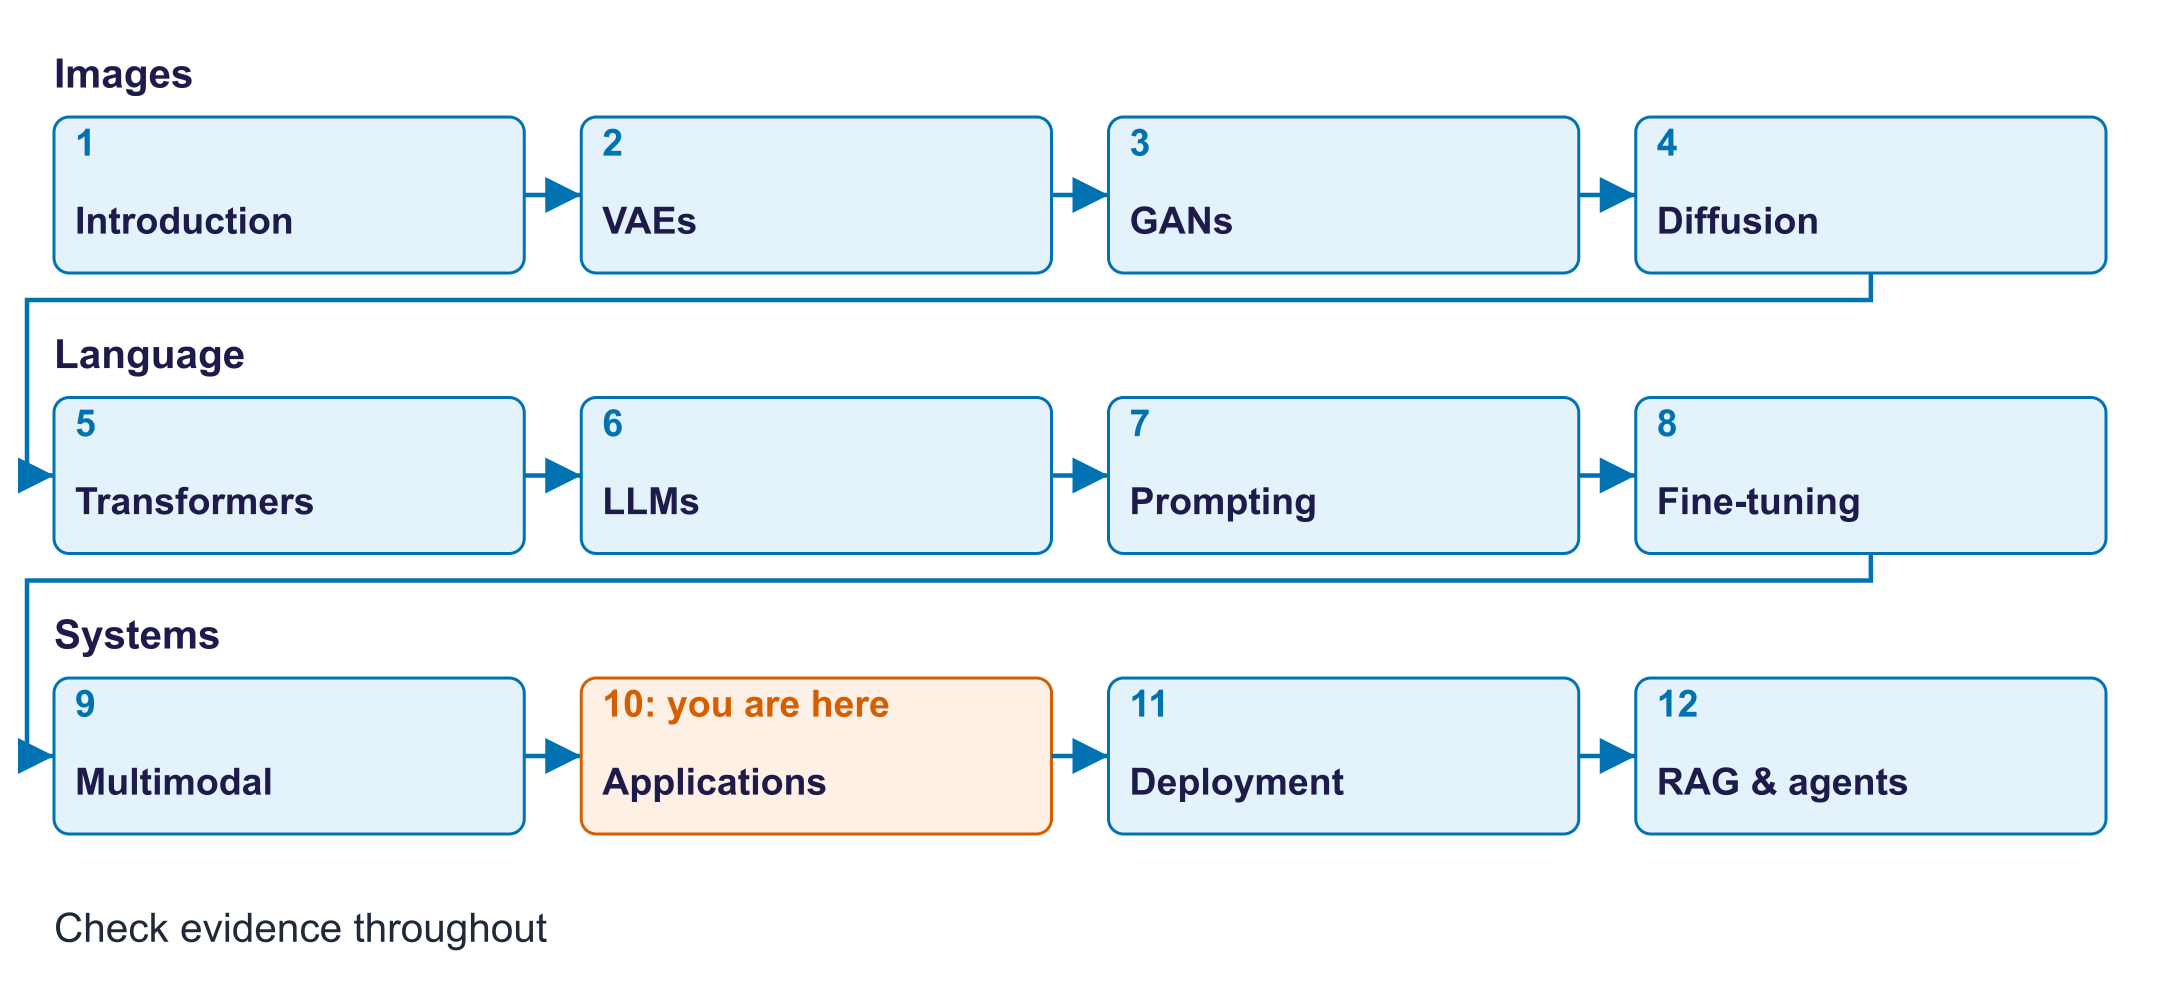

## Before running: choose the input-to-output route

This notebook contains several model pipelines. A **VLM** reads images and
questions to generate text. Diffusion creates or edits images. **TTS** turns
words into speech; **ASR** turns speech back into words.


A metric is a measurement for a particular question. A correct chart answer,
image-prompt alignment and speech intelligibility need different checks.

## Lab route and code map


| Diagram block | Code to find | Inspect before continuing |
|---|---|---|
| Create test inputs | `photos`, `fig_to_image`, `QA` | Known chart values and invoice fields. |
| Ask + verify | `ask`, `score`, `pope` | Full answers beside known evidence. |
| Generate + edit | `t2i`, `gen`, `edits` | Prompt, image and editing strength together. |
| Measure alignment | `clip_score`, `t2i_df` | Own-prompt and other-prompt comparisons. |
| Speech round trip | `tts`, `asr`, `wer` | Original words, transcript and audio. |
| Reshare image | `meta` | PNG labels before and after JPEG conversion. |

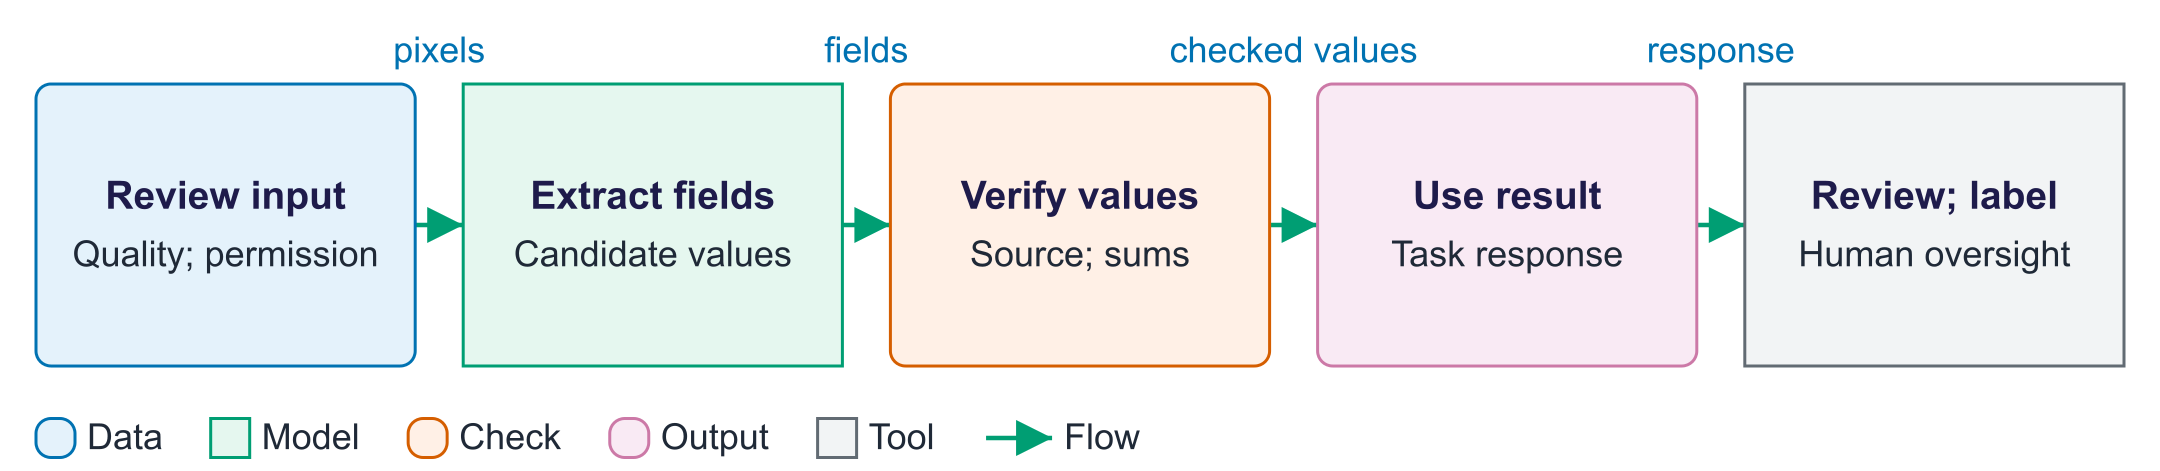

Automatic scores are partial checks. Inspect each output and its reference
before deciding that the pipeline succeeded.

**Read:** **VQA** means answering a question about an image; **OCR** means
reading text in an image. **Ground truth** is the answer known from the test
input, such as the values used to draw the chart. **Provenance** records
where an artifact came from and what happened to it.
**Run:** view the source image before calling a model, then read the full
answer beside the known answer. Use a separate check for each pipeline.
**Change:** for image editing, hold the input image, prompt and seed fixed
while changing `strength`.
**Check:** distinguish reading errors, arithmetic errors and unsupported
claims. A single overall percentage hides these different failure types.

**What/why:** install libraries for the core and preserved optional routes.
**Predict:** does installing a library also download every checkpoint?
**Expected output:** package installation completes; weights download only when a loading cell runs.
The builder pins this installation against the tested shared requirements.

In [ ]:
%pip install -q transformers==5.18.0 diffusers==0.40.0 accelerate soundfile pandas matplotlib scikit-learn ipywidgets==7.7.1
%pip install -q google-genai==2.29.0 ipywidgets==7.7.1 openai==3.28.0 python-dotenv==1.2.4

### Shared setup: choose, reproduce, check

This cell chooses CPU computation, fixes the random seed and prints package versions.
Expect a runtime record and no API request. `check()` prints helpful feedback.

Leave `USE_GEMINI = False` and `USE_OPENAI = False` for the complete local lab.
For an optional comparison, enable exactly one switch and rerun this setup cell.
`ask_model()` selects Gemini (`gemini-3.5-flash-lite`) or the OpenAI API (`gpt-4.1-mini`).
Both use a bounded retry, a shared 40-attempt ceiling and a local response cache.
Free quotas are account-specific; a failed request returns `None` for the local fallback.
Use only invented examples. Students in the EEA, UK and Switzerland should check
the [Gemini terms](https://ai.google.dev/gemini-api/terms) before opting in:
API-client distribution has a separate paid-service condition. Local tasks need no key or billing.
OpenAI API usage may incur charges, separately from ChatGPT subscriptions; check
[API pricing](https://developers.openai.com/api/docs/pricing) before opting in.
Use `GEMINI_API_KEY` or `OPENAI_API_KEY` in Colab Secrets or your local environment.
For local `.env` use, set `LOCAL_ENV_FILE` to that file's path. Secrets are read only after opt-in.
Use invented prompts only. OpenAI requests set `store=False`; this is not a promise of zero retention.

**Common errors:** a missing optional key means use the local result; a package import
error means check the selected kernel and install cell. Change only one switch at a time.

In [ ]:
"""Shared notebook setup, injected by the builder after package installation."""
import importlib.metadata
import importlib.util
import hashlib
import json
import os
from pathlib import Path
import platform
import random
import time

import numpy as np
import torch

# Change a switch only when you choose an optional route. Enable one API at most.
USE_GPU = False
USE_GEMINI = False
USE_OPENAI = False
GEMINI_MODEL = "gemini-3.5-flash-lite"
OPENAI_MODEL = "gpt-4.1-mini"
# Local users may change this path to their private .env file; never upload that file.
LOCAL_ENV_FILE = ".env"
SEED = 42
SMOKE = os.environ.get("GENAI_LAB_SMOKE") == "1"
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
# The instructor runner's explicit --device cuda option is also an opt-in.
_gpu_opt_in = USE_GPU or os.environ.get("GENAI_RUNNER_GPU") == "1"
DEVICE = "cuda" if _gpu_opt_in and torch.cuda.is_available() and os.environ.get("GENAI_FORCE_CPU") != "1" else "cpu"
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# Small CPU jobs often run faster without oversubscribing the machine.
torch.set_num_threads(min(4, os.cpu_count() or 1))
if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)

def check(condition, ok_message, hint):
    """Give feedback without hiding what needs to be corrected."""
    print("✅ " + ok_message if bool(condition) else "Try again: " + hint)
    return bool(condition)

def _package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return "not installed"

RUNTIME_INFO = {
    "environment": "Colab" if IN_COLAB else "local",
    "python": platform.python_version(), "device": DEVICE, "seed": SEED,
    "platform": platform.platform(), "processor": platform.processor(), "logical_cpus": os.cpu_count(),
    "cpu_threads": torch.get_num_threads(),
    "packages": {name: _package_version(name) for name in (
        "torch", "transformers", "diffusers", "peft", "trl",
        "sentence-transformers", "google-genai", "openai", "python-dotenv", "ipywidgets")},
}
print("Runtime:", json.dumps(RUNTIME_INFO, sort_keys=True))
print("CPU is the default. Complete the core tasks before trying optional GPU or API work.")

_gemini_calls = 0
_openai_calls = 0
_gemini_cache = Path.cwd() / ".genai_cache"

def _optional_key(name):
    """Read a secret only after the student opts in; never display it."""
    if IN_COLAB:
        try:
            from google.colab import userdata
            key = userdata.get(name)
            if key:
                return key
        except Exception:
            pass
    key = os.environ.get(name)
    if key or IN_COLAB:
        return key
    # Read this one file only after explicit API opt-in. Do not change the environment.
    try:
        from dotenv import dotenv_values
        return dotenv_values(LOCAL_ENV_FILE).get(name)
    except Exception:
        return None

def _gemini_key():
    return _optional_key("GEMINI_API_KEY")

def ask_gemini(prompt, *, temperature=0.2, max_output_tokens=256):
    """Return optional synthetic-data text, or None to use the local model.

    Requests, including retries, are capped at 40 per notebook session.
    Actual free quotas and eligibility depend on the student's account.
    """
    global _gemini_calls
    if not USE_GEMINI or SMOKE:
        return None
    key = _gemini_key()
    if not key:
        print("Gemini key unavailable; continue with the local result.")
        return None
    request = {"model": GEMINI_MODEL, "prompt": prompt,
               "temperature": temperature, "max_output_tokens": max_output_tokens}
    digest = hashlib.sha256(json.dumps(request, sort_keys=True).encode("utf-8")).hexdigest()
    cache_file = _gemini_cache / (digest + ".json")
    try:
        if cache_file.exists():
            return json.loads(cache_file.read_text(encoding="utf-8"))["text"]
    except (OSError, ValueError, KeyError):
        pass
    try:
        from google import genai
        from google.genai import types
        client = genai.Client(api_key=key, http_options=types.HttpOptions(
            timeout=30000, retry_options=types.HttpRetryOptions(attempts=1)))
        for attempt in range(4):
            if _gemini_calls + _openai_calls >= 40:
                print("Notebook request ceiling reached; use the local result.")
                return None
            _gemini_calls += 1
            try:
                response = client.models.generate_content(
                    model=GEMINI_MODEL, contents=prompt,
                    config=types.GenerateContentConfig(
                        temperature=temperature, max_output_tokens=max_output_tokens),
                )
                text = response.text
                if not isinstance(text, str) or not text.strip():
                    return None
                try:
                    _gemini_cache.mkdir(exist_ok=True)
                    cache_file.write_text(json.dumps({"text": text}), encoding="utf-8")
                except OSError:
                    pass
                return text
            except Exception as error:
                # Error messages can contain request details, so display no raw exception.
                if getattr(error, "code", None) != 429 or attempt == 3:
                    print("Gemini unavailable; continue with the local result.")
                    return None
                time.sleep(2 ** attempt)
    except Exception:
        print("Gemini setup unavailable; continue with the local result.")
    finally:
        if "client" in locals() and hasattr(client, "close"):
            try:
                client.close()
            except Exception:
                pass
    return None

def ask_openai(prompt, *, temperature=0.2, max_output_tokens=256):
    """Return optional OpenAI API text, or None for the complete local fallback.

    API usage may incur charges and is separate from a ChatGPT subscription.
    The notebook ceiling counts both providers' attempts, including retries.
    """
    global _openai_calls
    if not USE_OPENAI or SMOKE:
        return None
    key = _optional_key("OPENAI_API_KEY")
    if not key:
        print("OpenAI key unavailable; continue with the local result.")
        return None
    request = {"provider": "openai", "model": OPENAI_MODEL, "prompt": prompt,
               "temperature": temperature, "max_output_tokens": max_output_tokens}
    digest = hashlib.sha256(json.dumps(request, sort_keys=True).encode("utf-8")).hexdigest()
    cache_file = _gemini_cache / (digest + ".json")
    try:
        if cache_file.exists():
            return json.loads(cache_file.read_text(encoding="utf-8"))["text"]
    except (OSError, ValueError, KeyError):
        pass
    try:
        from openai import OpenAI
        # The helper owns retries so each network attempt counts towards the ceiling.
        client = OpenAI(api_key=key, timeout=30.0, max_retries=0)
        for attempt in range(4):
            if _gemini_calls + _openai_calls >= 40:
                print("Notebook request ceiling reached; use the local result.")
                return None
            _openai_calls += 1
            try:
                response = client.responses.create(
                    model=OPENAI_MODEL, input=prompt, temperature=temperature,
                    max_output_tokens=max_output_tokens, store=False,
                )
                text = response.output_text
                if not isinstance(text, str) or not text.strip():
                    return None
                try:
                    _gemini_cache.mkdir(exist_ok=True)
                    cache_file.write_text(json.dumps({"text": text}), encoding="utf-8")
                except OSError:
                    pass
                return text
            except Exception as error:
                if getattr(error, "status_code", None) != 429 or attempt == 3:
                    print("OpenAI unavailable; continue with the local result.")
                    return None
                time.sleep(2 ** attempt)
    except Exception:
        print("OpenAI setup unavailable; continue with the local result.")
    finally:
        if "client" in locals() and hasattr(client, "close"):
            try:
                client.close()
            except Exception:
                pass
    return None

def ask_model(prompt, *, temperature=0.2, max_output_tokens=256):
    """Use the student's one selected API, otherwise return None for local work."""
    if SMOKE:
        return None
    if USE_GEMINI and USE_OPENAI:
        print("Choose one API switch; keep the other False. Use the local result for now.")
        return None
    if USE_GEMINI:
        return ask_gemini(prompt, temperature=temperature, max_output_tokens=max_output_tokens)
    if USE_OPENAI:
        return ask_openai(prompt, temperature=temperature, max_output_tokens=max_output_tokens)
    return None


**What/why:** select a bounded local route using the injected CPU setup.
**Predict:** how many model calls should the core make?
**Expected output:** CPU, the small VLM identifier, the image-size cap and disabled extension flag.
The core makes two captions, three known-value questions and two yes/no probes: seven short calls.
`GENAI_VLM` is an instructor checkpoint override, which changes the experiment and must be recorded.

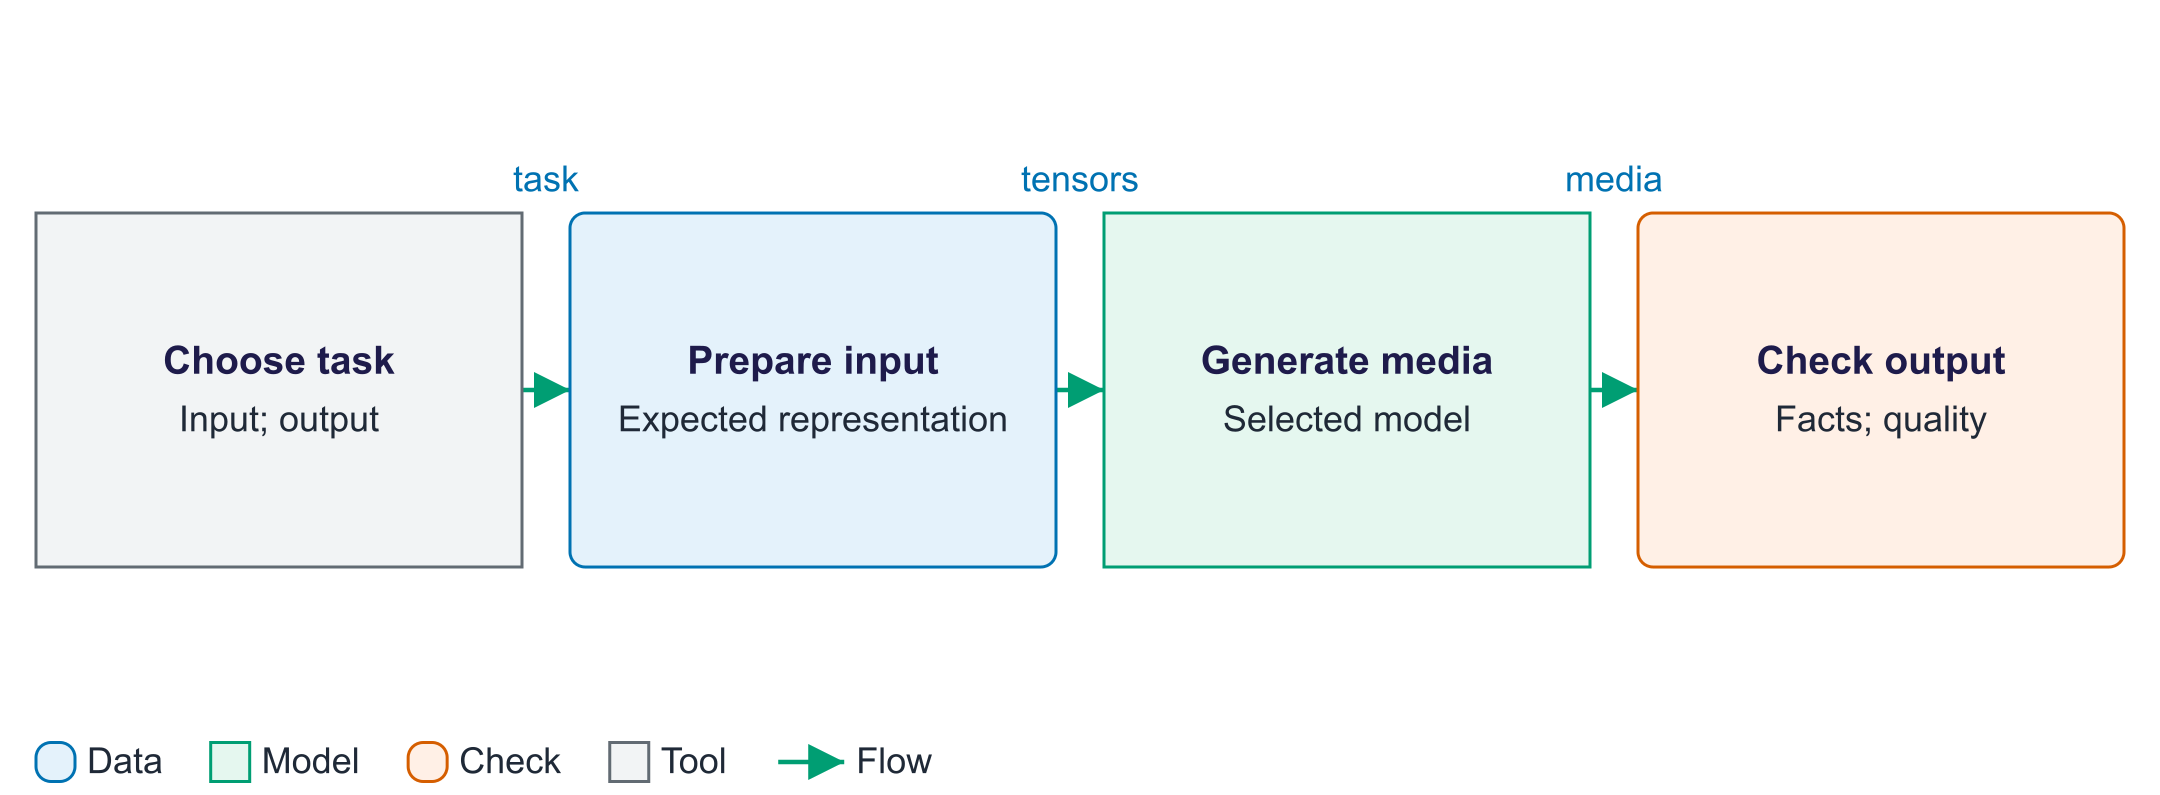
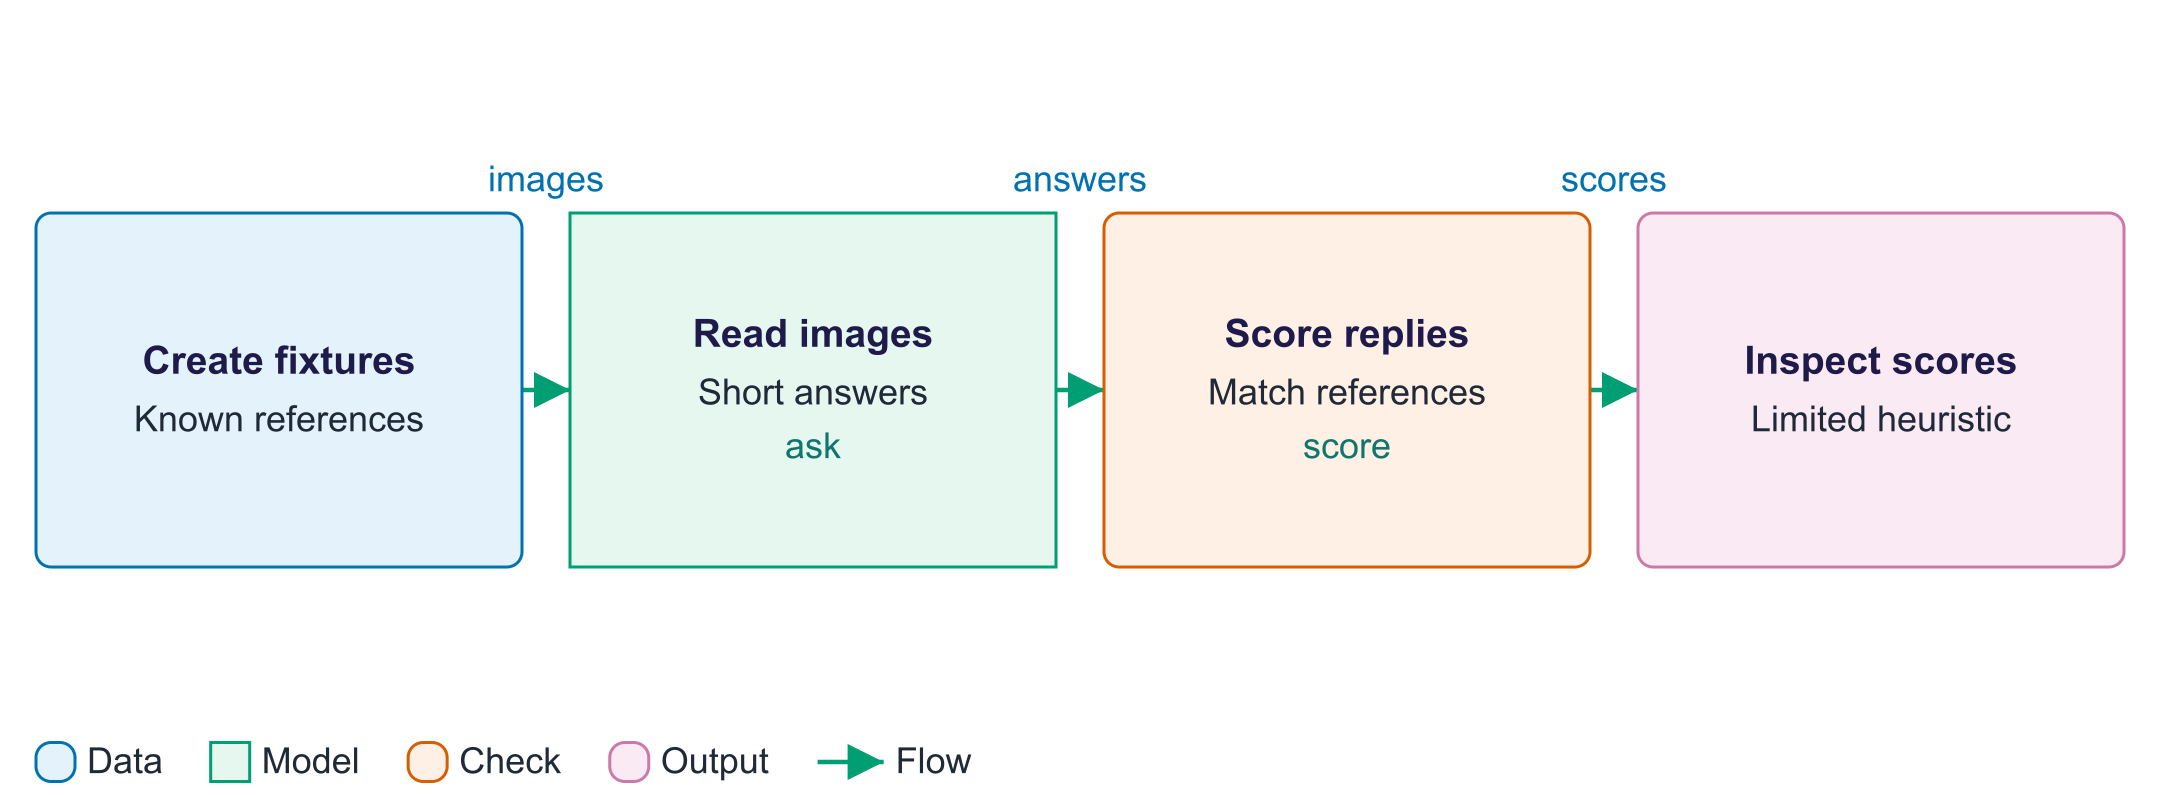

In [ ]:
import io
import os
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from PIL import Image, PngImagePlugin

# DEVICE, SEED, SMOKE, check and ask_model come from the single injected setup.
DTYPE = torch.float32  # Float32 also avoids older-GPU half-precision image failures.
RUN_STRETCH = False  # Optional diffusion, CLIP, TTS and ASR; never required for the core.
VLM_ID = os.environ.get("GENAI_VLM") or "HuggingFaceTB/SmolVLM-256M-Instruct"
MAX_IMAGE_SIDE = 384
MAX_ANSWER_TOKENS = 32
print("device:", DEVICE, "| VLM:", VLM_ID, "| image cap:", MAX_IMAGE_SIDE, "| stretch:", RUN_STRETCH)


def fig_to_image(fig, dpi=100):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    return Image.open(buf).convert("RGB")

## Part 1 · Image → text with a vision-language model

A VLM is a vision encoder + projector + LLM (week 9). We ask it to describe images and answer questions.
The **processor** prepares both pixels and question tokens. The **projector**
maps visual features into a representation the language component can use.
Follow `ask`: format the message, prepare tensors, generate, remove the input
prefix, then decode the new tokens. Generating this caption does not train
the model or update its knowledge.

**Core:** trace a real caption and inspect every claim. **Change one thing:** request a shorter caption.
**Optional stretch:** compare another permitted VLM checkpoint on the same inputs.
> **Common errors:** a missing download needs connectivity; invented objects require source review, not a lower score threshold.

**What/why:** Load a VLM and trace image/question preparation.

**Predict:** Why decode only tokens after input_ids?

**Expected output:** Photographs and captions; image-reading claims need inspection.

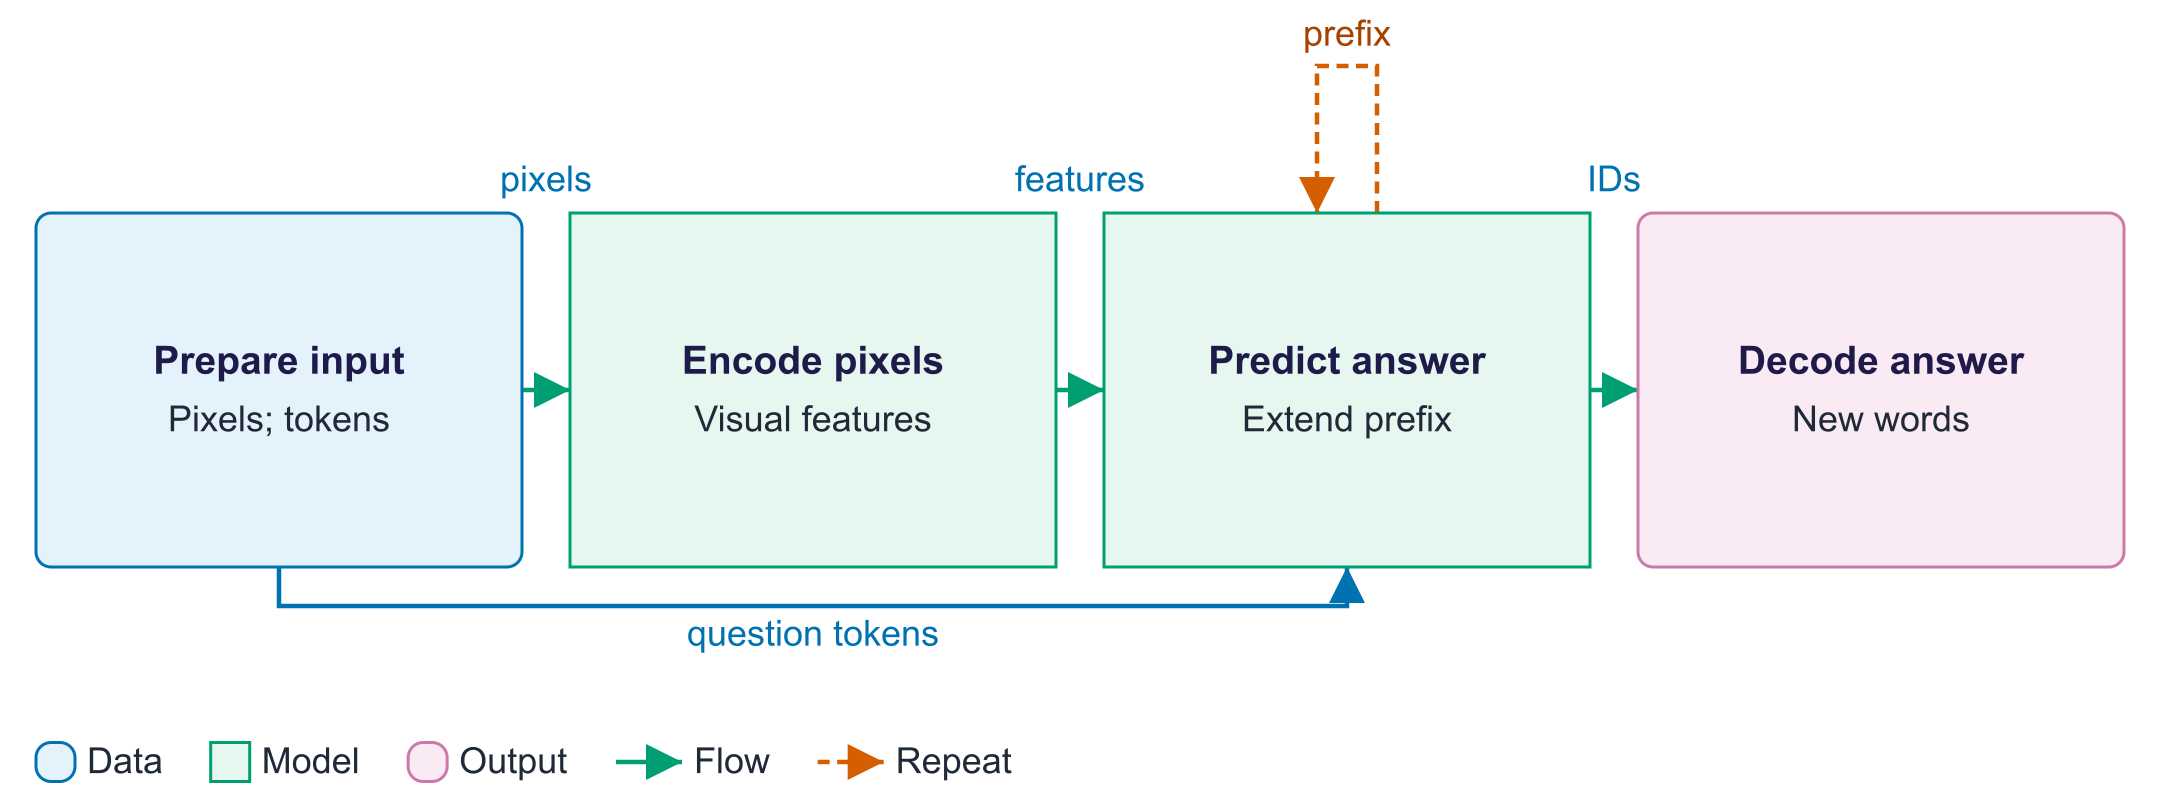

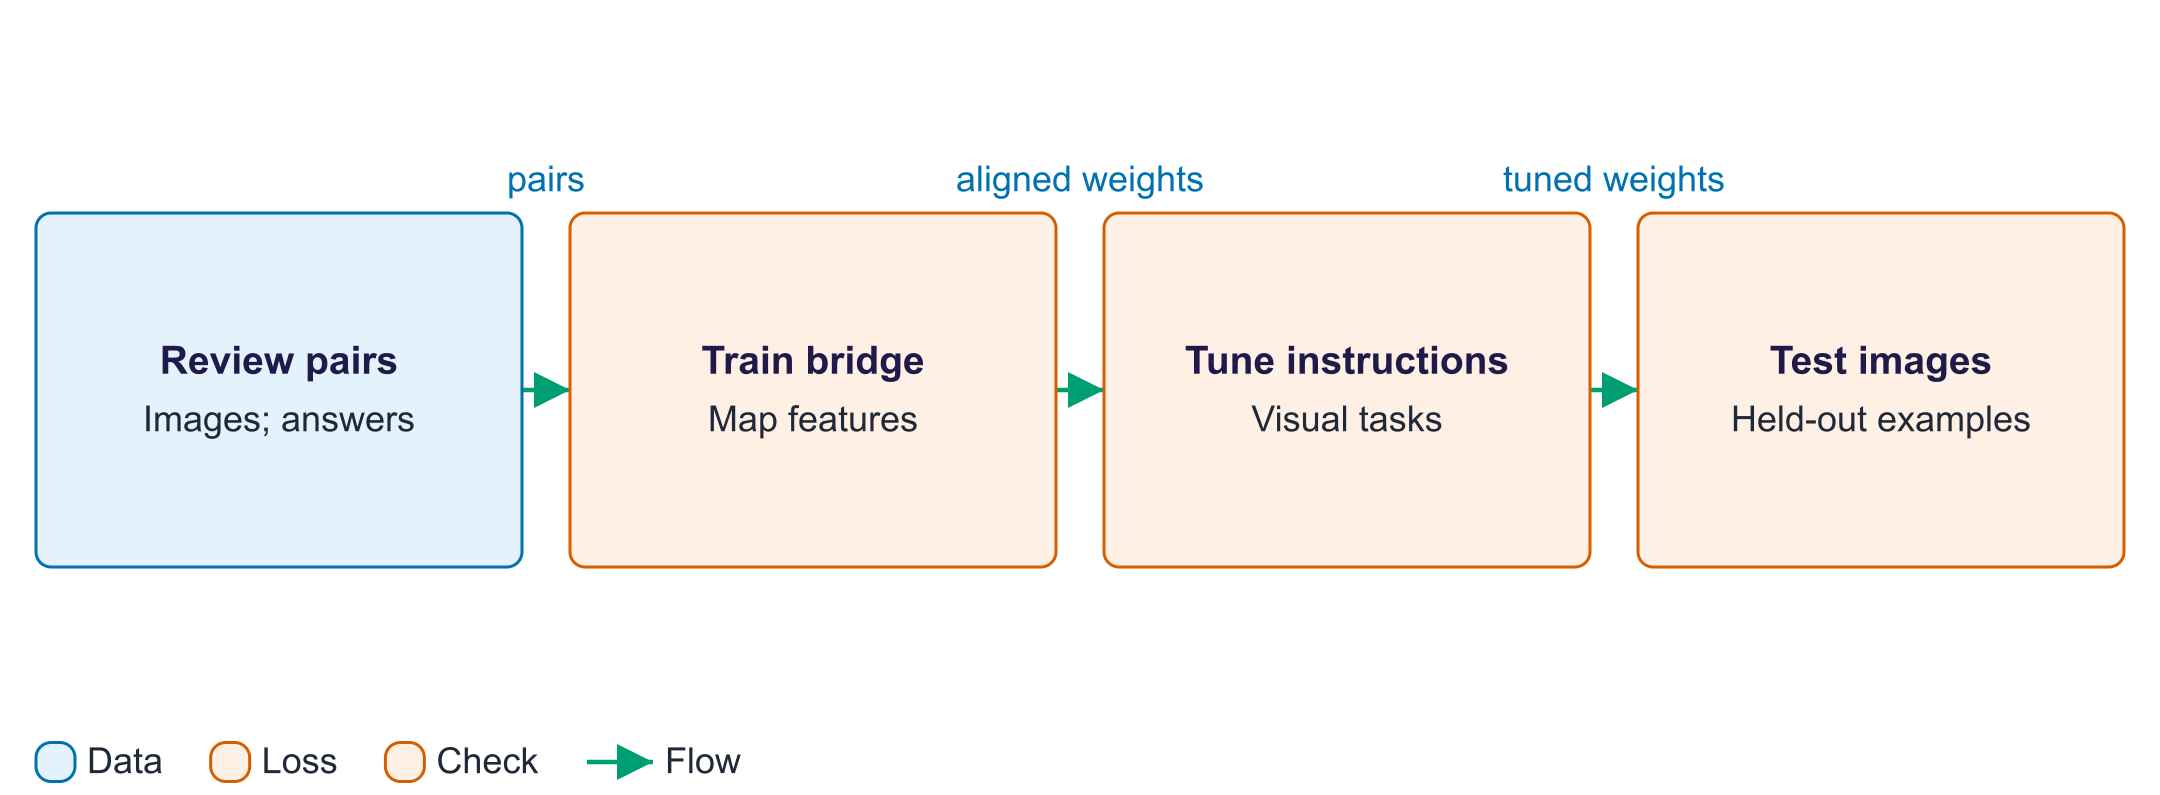

In [ ]:
from sklearn.datasets import load_sample_image
from transformers import AutoModelForImageTextToText, AutoProcessor

vlm_proc = AutoProcessor.from_pretrained(VLM_ID)
vlm = AutoModelForImageTextToText.from_pretrained(VLM_ID, dtype=DTYPE).to(DEVICE).eval()


def ask(image, question, max_new_tokens=MAX_ANSWER_TOKENS):
    # Preserve the aspect ratio and cap visual work before processing.
    image = image.copy()
    image.thumbnail((MAX_IMAGE_SIDE, MAX_IMAGE_SIDE))
    # The placeholder in the chat message identifies where image data belongs.
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    prompt = vlm_proc.apply_chat_template(msgs, add_generation_prompt=True)
    inputs = vlm_proc(text=prompt, images=[image], return_tensors="pt").to(DEVICE)
    if not getattr(ask, "shapes_shown", False):
        print("model tensor shapes:", {k: tuple(v.shape) for k, v in inputs.items() if hasattr(v, "shape")})
        ask.shapes_shown = True
    with torch.no_grad():
        out = vlm.generate(**inputs, max_new_tokens=min(16 if SMOKE else MAX_ANSWER_TOKENS, max_new_tokens), do_sample=False)
    # Generation returns the input prefix too; decode only the new answer.
    return vlm_proc.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


photos = {"temple": Image.fromarray(load_sample_image("china.jpg")), "flower": Image.fromarray(load_sample_image("flower.jpg"))}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, (k, im) in zip(ax, photos.items()):
    a.imshow(im); a.axis("off"); a.set_title(k)
plt.show()  # CAPTION_FIGURE
captions = {}
for k, im in photos.items():
    captions[k] = ask(im, "Describe this image in one sentence.")
    print(f"{k}: {captions[k]}")

## Part 2 · Cross-modal reasoning over charts and documents

We **generate** a chart and a document image ourselves, so we know the correct answers exactly.
Before asking the VLM, work out one answer yourself: the ticket total is
`12 + 30 + 18 + 25 + 9 = 94`. The invoice total is `20 + 15 = 35 EUR`.
These are checks based on the input data, rather than on another model's opinion.

**Core:** verify three short reading questions and compute the known totals. **Change one thing:** add a chart value in the source.
**Optional stretch:** include all six questions and categorise errors.
> **Common errors:** a correct sum can use misread numbers; valid JSON or a matching substring does not establish truth.

**What/why:** Draw a chart and fictional invoice from known values.

**Predict:** What is 12 + 30 + 18 + 25 + 9?

**Expected output:** Chart, invoice and QA references; the ticket total is 94.

In [ ]:
days, tickets = ["Mon", "Tue", "Wed", "Thu", "Fri"], [12, 30, 18, 25, 9]
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.bar(days, tickets, color="tab:blue"); ax.set_title("Help-desk tickets per day"); ax.set_ylabel("tickets")
chart = fig_to_image(fig)

fig, ax = plt.subplots(figsize=(5, 3.6)); ax.axis("off")
doc_lines = ["INVOICE  No. 2027-0415", "Date: 3 March 2027", "Customer: Dublin Robotics Ltd", "",
             "GPU hours (T4)      40 x 0.50 EUR   20.00", "Storage (TB-month)   2 x 7.50 EUR   15.00", "",
             "TOTAL DUE                         35.00 EUR", "Payment due within 30 days"]
for i, line in enumerate(doc_lines):
    ax.text(0.02, 0.95 - i * 0.1, line, family="monospace", fontsize=11, va="top")
document = fig_to_image(fig)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].imshow(chart); ax[0].axis("off"); ax[1].imshow(document); ax[1].axis("off")
plt.show()  # CHART_FIGURE

QA = [
    (chart, "Which day had the most tickets? Answer with the day only.", "tue"),
    (chart, "How many tickets were there on Thursday? Answer with a number.", "25"),
    (chart, "What is the total number of tickets from Monday to Friday? Answer with a number.", "94"),
    (document, "What is the invoice number? Answer with the number only.", "2027-0415"),
    (document, "What is the total due in EUR? Answer with the number only.", "35"),
    (document, "Who is the customer? Answer with the name only.", "dublin robotics"),
]
invoice_lines = [(40, 0.50), (2, 7.50)]
invoice_total = sum(quantity * price for quantity, price in invoice_lines)
chart_total = sum(tickets)
print("known chart total:", chart_total, "| known invoice total:", invoice_total, "EUR")
check(chart_total == 94 and invoice_total == 35, "Known fixture totals checked.", "Check quantities, prices and addition.")

**TODO 1:** complete `score(answer, gold)`: normalise text (lower-case, remove commas, preserve signs) and return 1 if the reference string appears in it (for numbers, compare the first signed number found, e.g. "35.00" counts for "35", but "-35" does not).

This is a deliberately small checking heuristic. A matching substring can
occur in a wrong sentence, and the first number can be unrelated to the
requested field. Read the model answer beside the chart or invoice too.

**Hint:** use `re.fullmatch` to recognise a numeric reference, `re.findall` to parse answer numbers, and `return int(...)`.
Run `check_score()` immediately afterwards; test mismatches as well as matches.

**What/why:** Complete the small answer-checking heuristic.

**Predict:** Could a substring appear in an otherwise wrong answer?

**Expected output:** three core QA rows and heuristic accuracy; inspect full replies beside known reference values.

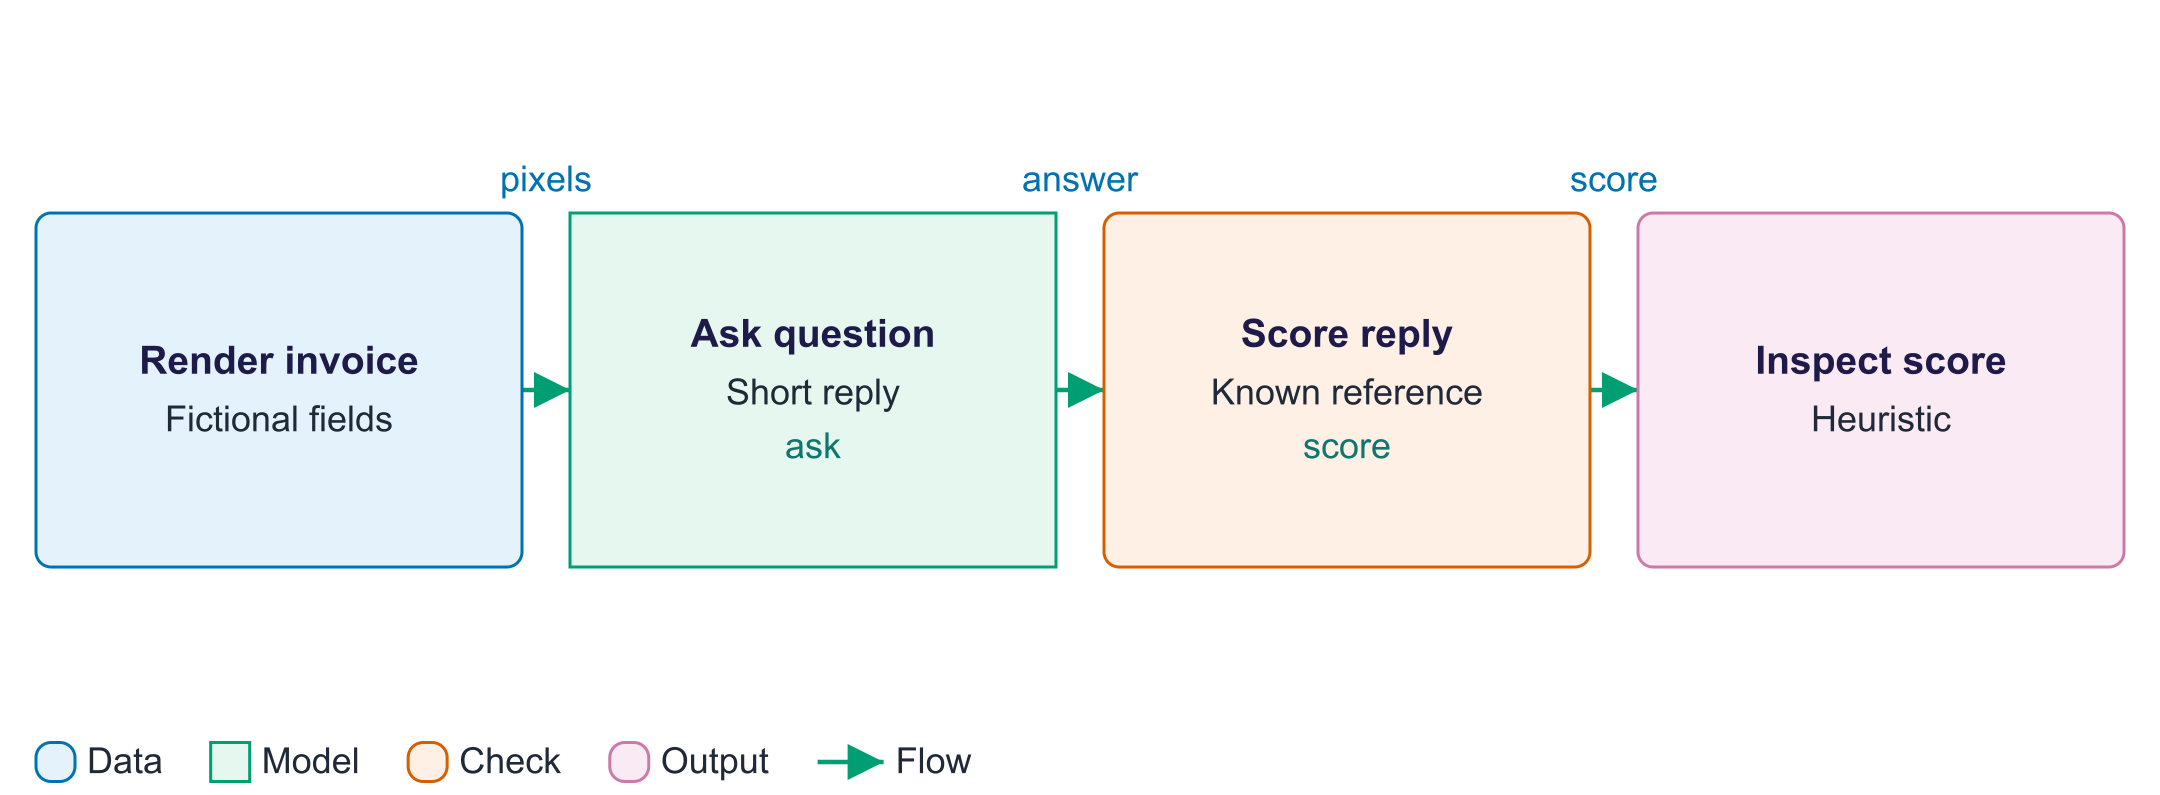

In [ ]:
def score(answer, gold):
    a = answer.lower().replace(",", "").replace("−", "-")
    g = gold.lower().replace(",", "").replace("−", "-")
    return 0  # TODO 1: implement the matching heuristic.


def check_score():
    """Check decimal/sign equivalence, unrelated first numbers and text mismatches."""
    cases=[("35.00 EUR", "35", 1), ("36 EUR", "35", 0), ("Tue", "tue", 1), ("Monday", "tue", 0),
           ("1,035 EUR", "1035", 1), ("2 items cost 35 EUR", "35", 0), ("-25", "25", 0),
           ("−25", "25", 0), ("+25.00", "25", 1), ("-.50 EUR", "-0.5", 1), ("TUE", "Tue", 1)]
    try:
        return check(all(score(a,g)==want for a,g,want in cases), "TODO 1: score cases checked.",
                     "Normalise lower case and commas; preserve signs and compare the first number for numeric references; return 0 or 1.")
    except (TypeError, ValueError, AttributeError):
        return check(False, "", "score needs strings, a numeric comparison and an explicit return value.")

check_score()


rows = []
for im, q, gold in [QA[i] for i in (0, 1, 3)]:
    t0 = time.time()
    ans = ask(im, q, max_new_tokens=20)
    rows.append({"question": q[:55], "gold": gold, "answer": ans, "correct": int(score(ans, gold) == 1), "seconds": round(time.time() - t0, 1)})
qa_df = pd.DataFrame(rows)
print("accuracy:", qa_df.correct.mean())
qa_df

**What/why:** compare a synthetic invoice explanation through the shared optional provider.
**Predict:** what happens with both provider switches disabled?
**Expected output:** a complete local calculation; no API is required or called by the default route.
Enable exactly one of `USE_GEMINI` or `USE_OPENAI` in the injected setup only for this optional text comparison.
The request contains invented numbers, with no image or personal information. Check the arithmetic regardless of provider.

In [ ]:
local_explanation = "Known fixture: 40 × 0.50 + 2 × 7.50 = 20 + 15 = 35 EUR. Check extraction separately."
hosted_answer = None
if (USE_GEMINI or USE_OPENAI) and not SMOKE:
    hosted_answer = ask_model("For a fictional invoice, explain 40 times 0.50 plus 2 times 7.50. Distinguish reading values from arithmetic.",
                              max_output_tokens=120)
comparison_answer = hosted_answer if hosted_answer is not None else local_explanation
print(comparison_answer)

### Multimodal hallucination probe (POPE-style)
Ask yes/no questions about objects that **are** and **are not** in the image. A reliable model says "no" for absent objects.

**What/why:** Probe both visible and absent items.

**Predict:** Should a flower photo be described as containing a dog?

**Expected output:** two yes/no rows with full replies; this classroom probe is not the full benchmark.

In [ ]:
probes = [(photos["flower"], "Is there a flower in the image? Answer yes or no.", "yes"),
          (photos["flower"], "Is there a dog in the image? Answer yes or no.", "no"),
          (photos["temple"], "Is there a building in the image? Answer yes or no.", "yes"),
          (photos["temple"], "Is there a car in the image? Answer yes or no.", "no"),
          (chart, "Does the chart show data for Saturday? Answer yes or no.", "no"),
          (document, "Does the invoice mention VAT? Answer yes or no.", "no")]
def yes_no_label(answer):
    """Parse a leading yes/no word; uncertainty and unrelated prefixes are non-answers."""
    match = re.match(r"^\s*(yes|no)\b", answer.lower())
    return match.group(1) if match else None


def check_yes_no_label():
    cases = [("Yes, a flower.", "yes"), (" NO, no dog.", "no"), ("Nobody can tell.", None),
             ("Not enough information.", None), ("Yesterday it rained.", None), ("", None)]
    return check(all(yes_no_label(answer) == expected for answer, expected in cases),
                 "Standalone yes/no labels checked; non-answers cannot score as no.",
                 "Match a complete leading yes or no word, rather than an unbounded character prefix.")


check_yes_no_label()
pope = pd.DataFrame([{"question": q, "gold": g, "answer": ask(im, q, 5)} for im, q, g in probes[:2]])
pope["correct"] = [int(yes_no_label(a) == g) for a, g in zip(pope.answer, pope.gold)]
pope

**What/why:** change preview resolution without triggering model inference.
**Predict:** which chart labels become hard to read at a small size?
**Expected output:** an image and its pixel dimensions. The slider redraws a preview only; model inference stays in `ask`.
To test the effect on answers, choose one size explicitly and rerun one question, keeping other settings fixed.

In [ ]:
import ipywidgets as widgets
from IPython.display import display

def preview_resolution(side):
    preview = chart.copy()
    preview.thumbnail((side, side))
    print("preview pixels (width, height):", preview.size)
    display(preview)

widgets.interact(preview_resolution, side=widgets.IntSlider(value=384, min=96, max=768, step=96, description="Pixels"))

✍️ **Question 1.** How accurate was the VLM on charts and documents? Which questions failed: reading, counting/arithmetic, or hallucination? What would you change before using such a model to process invoices?

*✍️ Write your answer here.*

## Part 3 · Text → image and image → image

**SD-Turbo** is a distilled diffusion model (week 4) that generates in 1–4 steps without classifier-free guidance.

**Core:** inspect the archived image strips and explain preserved structure at each strength.
**Change one thing:** predict the effect of strength before revealing an archived edit.
**Optional stretch:** set `RUN_STRETCH = True` before the optional loading cells to execute real diffusion and CLIP.
> **Common errors:** first downloads and CPU diffusion may be slow; reduce prompts, then compare equal seeds and settings.

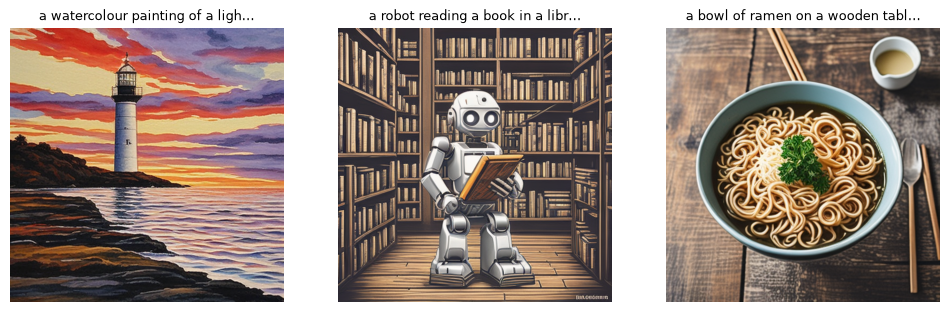
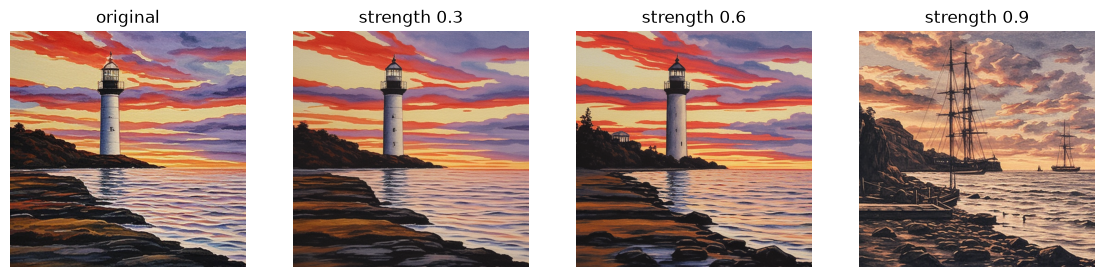

**What/why:** Generate three images with a low-step diffusion route.

**Predict:** Does a fast output guarantee prompt accuracy?

**Expected output:** a skipped-extension message in the core; three fresh images only when `RUN_STRETCH` is enabled.

In [ ]:
t2i_df = pd.DataFrame()
speech_df = pd.DataFrame()
gen, edits = [], []
T2I_ID = "hf-internal-testing/tiny-sd-pipe" if SMOKE else "stabilityai/sd-turbo"
if RUN_STRETCH:
    from diffusers import AutoPipelineForImage2Image, AutoPipelineForText2Image

    if SMOKE:
        t2i = AutoPipelineForText2Image.from_pretrained("hf-internal-testing/tiny-sd-pipe", safety_checker=None).to(DEVICE)
        SIZE, STEPS = 64, 2
    else:
        t2i = AutoPipelineForText2Image.from_pretrained("stabilityai/sd-turbo", torch_dtype=DTYPE).to(DEVICE)
        SIZE, STEPS = 512, 2
    t2i.set_progress_bar_config(disable=True)
    prompts = ["a watercolour painting of a lighthouse at sunset",
               "a robot reading a book in a library, digital art",
               "a bowl of ramen on a wooden table, photograph"]
    gen = [t2i(p, num_inference_steps=STEPS, guidance_scale=0.0, height=SIZE, width=SIZE,
               generator=torch.Generator("cpu").manual_seed(i)).images[0] for i, p in enumerate(prompts)]
    fig, ax = plt.subplots(1, 3, figsize=(12, 4.3))
    for a, im, p in zip(ax, gen, prompts):
        a.imshow(im); a.axis("off"); a.set_title(p[:32] + "…", fontsize=9)
    plt.show()  # T2I_FIGURE
else:
    print("Diffusion extension skipped; inspect the archived image strips above.")

**TODO 2:** image → image. Use the same model as an img2img pipeline (`AutoPipelineForImage2Image.from_pipe(t2i)`) to restyle the lighthouse image with the prompt "the same scene as a pencil sketch" at `strength` 0.3, 0.6 and 0.9 (with `num_inference_steps=4`; the effective steps are `steps × strength`).

Image-to-image perturbs the input representation before denoising it with
the new prompt. Compare how much of the original scene survives each
strength. The low step count also makes the effective schedule discrete.
Here `4 * strength` is truncated to a whole number of starting denoising
steps: the settings use 1, 2 and 3 steps respectively. Larger strength
starts from a noisier input representation and can change the scene more.
It is different from guidance scale, which weights text guidance during sampling.

**Hint:** reuse `t2i` with `from_pipe`; hold the source image and seed fixed and iterate over `(0.3, 0.6, 0.9)`.
`check_edits()` uses distinct probe images to verify three calls, settings and returned-image correspondence before optional inference.

**What/why:** Complete image editing at three noise strengths.

**Predict:** Which setting permits the largest change?

**Expected output:** a semantic probe check in the core; original plus three real edits only in the extension. Effective steps are discrete.

In [ ]:
def make_edits(edit_pipeline, source):
    """Keep input, prompt and seed fixed while changing only the requested strength."""
    return [source] * 3  # TODO 2: call the editing pipeline once per strength.


def check_edits():
    """Probe call semantics without loading or running diffusion."""
    from types import SimpleNamespace
    source = Image.new("RGB", (8, 8), "white")
    calls, expected_outputs = [], []
    def probe(prompt, **settings):
        calls.append((prompt, settings))
        output = Image.new("RGB", source.size, (20 * len(calls), 0, 0))
        expected_outputs.append(output)
        return SimpleNamespace(images=[output])
    try:
        result = make_edits(probe, source)
        valid = len(calls)==3 and isinstance(result, list) and len(result)==3
        valid = valid and [settings["strength"] for _,settings in calls]==[0.3,0.6,0.9]
        valid = valid and all(prompt=="the same scene as a pencil sketch" and settings["image"] is source
                             and settings["num_inference_steps"]==4 and settings["guidance_scale"]==0.0
                             and settings["generator"].initial_seed()==0 for prompt,settings in calls)
        valid = valid and all(isinstance(im, Image.Image) and im.size==source.size for im in result)
        valid = valid and all(np.array_equal(np.asarray(actual), np.asarray(expected))
                              for actual, expected in zip(result, expected_outputs))
    except (TypeError, ValueError, KeyError, AttributeError):
        valid = False
    return check(valid, "TODO 2: settings and each returned pipeline image checked with distinct probes.",
                 "Call the pipeline at strengths 0.3, 0.6, 0.9 with fixed source/prompt/seed, four steps and zero guidance; return its corresponding image each time.")


check_edits()
if RUN_STRETCH:
    i2i = AutoPipelineForImage2Image.from_pipe(t2i)
    edits = make_edits(i2i, gen[0])
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.8))
    for a, im, title in zip(ax, [gen[0]] + edits, ["original", "strength 0.3", "strength 0.6", "strength 0.9"]):
        a.imshow(im); a.axis("off"); a.set_title(title)
    plt.show()  # I2I_FIGURE
else:
    print("Diffusion inference skipped; the TODO 2 semantic probe does not generate an image.")

### Evaluate prompt alignment with CLIP score (from weeks 4 and 9)
A score compares image and text embeddings. It does not verify every object,
the absence of artefacts or the correctness of written numbers in the image.

**What/why:** Measure image/prompt cosine alignment.

**Predict:** Is a CLIP score a probability of being correct?

**Expected output:** a skipped-extension message in the core; fresh own/other-prompt scores only after optional image generation.

In [ ]:
if RUN_STRETCH:
    from transformers import CLIPModel, CLIPProcessor

    clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
    cproc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")


    @torch.no_grad()
    def clip_score(image, text):
        inp = cproc(text=[text], images=image, return_tensors="pt", padding=True).to(DEVICE)
        o = clip(**inp)
        return 100 * torch.nn.functional.cosine_similarity(o.image_embeds, o.text_embeds).item()


    rows = [{"prompt": p[:40], "CLIP score (own prompt)": round(clip_score(im, p), 1),
             "CLIP score (other prompts, mean)": round(np.mean([clip_score(im, q) for q in prompts if q != p]), 1)} for im, p in zip(gen, prompts)]
    t2i_df = pd.DataFrame(rows)
    t2i_df
else:
    print("CLIP extension skipped; compare the archived prompt scores in the lecture notes.")

## Part 4 · Text → speech → text

**TODO 3:** synthesise speech with MMS-TTS (`facebook/mms-tts-eng`, a VITS model), transcribe it with Whisper, and compute the word error rate against the original text (reuse the WER function from week 9, provided below).

Keep the waveform's sampling rate attached when passing it to ASR. WER
measures word disagreement after normalisation; listen to the generated
audio as well, because recovered words do not measure voice naturalness.
A **waveform** is a list of sound samples, and the **sampling rate** is how
many samples represent one second. An array of 16,000 samples at 16,000 Hz
lasts one second. Keep these units with the array so ASR interprets the sound
at the correct speed. The round trip tests both the synthesiser and recogniser.

**Core:** run the provided word-edit algorithm on short text and inspect the archived speech transcript examples.
**Change one thing:** replace one reference word and predict WER.
**Optional stretch:** use `RUN_STRETCH` to synthesise and transcribe real audio.
> **Common errors:** keep the sampling rate with the waveform; zero WER is not a naturalness or consent check.

**Hint:** extract `waveform[0]`, move it to CPU, obtain `tts.config.sampling_rate`, and pass both to ASR.
`check_speech()` probes the actual sample values, a non-default true sampling rate and recogniser call before optional inference.

**What/why:** Complete speech synthesis, transcription and word comparison.

**Predict:** Does zero WER prove natural-sounding speech?

**Expected output:** semantic speech probes and a worked WER in the core; a fresh speech table and WAV only in the extension.

In [ ]:
def wer(ref, hyp):
    r, h = re.sub(r"[^\w\s]", "", ref.lower()).split(), re.sub(r"[^\w\s]", "", hyp.lower()).split()
    d = np.zeros((len(r) + 1, len(h) + 1), dtype=int)
    d[:, 0], d[0, :] = range(len(r) + 1), range(len(h) + 1)
    for i in range(1, len(r) + 1):
        for j in range(1, len(h) + 1):
            d[i, j] = min(d[i - 1, j] + 1, d[i, j - 1] + 1, d[i - 1, j - 1] + (r[i - 1] != h[j - 1]))
    return d[-1, -1] / max(1, len(r))



def synthesise_and_transcribe(sentence, synthesiser, tokenizer, recogniser):
    """Preserve actual waveform data and sampling rate throughout the round trip."""
    return np.zeros(16000, dtype=np.float32), 16000, ""  # TODO 3: synthesise, preserve rate and transcribe.


def check_speech():
    """Catch a changed waveform, hardcoded sampling rate or omitted recogniser call."""
    from types import SimpleNamespace
    expected=np.array([0.1,-0.2,0.3,-0.4], dtype=np.float32)
    seen=[]
    class ProbeBatch(dict):
        def to(self, device):
            seen.append(("device",device))
            return self
    def probe_tokenizer(sentence, **settings):
        seen.append(("tokens",sentence,settings))
        return ProbeBatch(input_ids=torch.tensor([[1,2]]))
    class ProbeSynthesiser:
        config=SimpleNamespace(sampling_rate=22050)
        def __call__(self, **settings):
            seen.append(("synthesis",settings))
            return SimpleNamespace(waveform=torch.tensor(expected).reshape(1,-1))
    def probe_recogniser(packet):
        seen.append(("recognition",packet))
        return {"text":"  known reference words  "}
    try:
        waveform, rate, transcript=synthesise_and_transcribe("known reference words",ProbeSynthesiser(),probe_tokenizer,probe_recogniser)
        recognised=[entry[1] for entry in seen if entry[0]=="recognition"]
        tokens=[entry for entry in seen if entry[0]=="tokens"]
        valid=(isinstance(waveform,np.ndarray) and waveform.shape==expected.shape and np.allclose(waveform,expected)
               and rate==22050 and transcript=="known reference words" and len(recognised)==1 and len(tokens)==1)
        valid=valid and np.array_equal(recognised[0]["raw"],expected) and recognised[0]["sampling_rate"]==22050
        valid=valid and tokens[0][1]=="known reference words" and tokens[0][2].get("return_tensors")=="pt"
    except (TypeError, ValueError, KeyError, AttributeError):
        valid=False
    return check(valid,"TODO 3: waveform, true sampling rate and recogniser text checked with probes.",
                 "Use waveform[0], convert it to NumPy, pass its configured sampling rate to ASR, and return stripped text.")


def check_wer():
    cases=[("the red cup","the blue cup",1/3),("a b","a b c",1/2),("a b c","a c",1/3),("Same words!","same words",0)]
    return check(all(abs(wer(r,h)-expected)<1e-8 for r,h,expected in cases),
                 "WER substitution, insertion, deletion and normalisation checked.",
                 "Use reference length and the minimum word-edit path; normalise punctuation and case.")


check_speech()
print("worked WER: one substitution in three words =",wer("the red cup","the blue cup"))
check_wer()
if RUN_STRETCH:
    from transformers import AutoTokenizer, VitsModel, pipeline
    tts_tok=AutoTokenizer.from_pretrained("facebook/mms-tts-eng")
    tts=VitsModel.from_pretrained("facebook/mms-tts-eng").to(DEVICE).eval()
    asr=pipeline("automatic-speech-recognition", model="openai/whisper-tiny" if SMOKE else "openai/whisper-base",device=0 if DEVICE=="cuda" else -1)
    sentences=["The lab opens at nine in the morning.","Generative models can create images, text and speech.",
               "Please submit your project report by the fifteenth of March."]
    rows=[]
    for sentence in (sentences[:1] if SMOKE else sentences):
        wav,sr,hyp=synthesise_and_transcribe(sentence,tts,tts_tok,asr)
        rows.append({"text":sentence,"transcript":hyp,"WER":round(wer(sentence,hyp),3),"seconds of audio":round(len(wav)/sr,1)})
    sf.write("tts_example.wav",wav,sr)
    speech_df=pd.DataFrame(rows)
    display(speech_df)
else:
    print("TTS/ASR inference skipped; core semantic probes and real word-edit algorithm ran.")

✍️ **Question 2.** What does the TTS → ASR round trip measure, and what does it not measure? How would you evaluate a voice assistant's speech output properly?

*✍️ Write your answer here.*

## Part 5 · Provenance: labels can disappear

**Core:** save the synthetic chart fixture with honest metadata, reload it, and resave as JPEG.
**Change one thing:** alter a label before saving and observe that unsigned text is editable.
**Optional stretch:** when diffusion has run, label its first generated image instead.
> **Common errors:** PNG text fields are unsigned classroom labels; they are not signed C2PA credentials or proof of depicted truth.

**TODO 4:** add `ai_generated`, `model` and `prompt` fields to `PngInfo` using the selected source values.
For a real SD-Turbo output these are `true`, `stabilityai/sd-turbo` and its prompt.
For the core fixture use `false`, `matplotlib/synthetic-fixture` and its rendering description.
**Hint:** call `meta.add_text(name, value)` once for each field; `check_metadata()` checks labels and their loss after JPEG conversion.
The experiment tests ordinary metadata loss, rather than evaluating C2PA or a watermark detector.

**What/why:** Add illustrative PNG text labels and resave as JPEG.

**Predict:** Which provenance information might disappear?

**Expected output:** honest fixture/generated-image labels before and after JPEG conversion; these unsigned fields are not C2PA.

In [ ]:
label_image = gen[0] if RUN_STRETCH else chart
label_ai = "true" if RUN_STRETCH else "false"
label_model = T2I_ID if RUN_STRETCH else "matplotlib/synthetic-fixture"
label_prompt = prompts[0] if RUN_STRETCH else "Known help-desk ticket chart rendered from source values."
meta = PngImagePlugin.PngInfo()
pass  # TODO 4: add the three honest labels to meta.
label_image.save("generated.png", pnginfo=meta)
with Image.open("generated.png") as saved:
    png_metadata = dict(saved.text)
    saved.convert("RGB").save("reshared.jpg", quality=90)
with Image.open("reshared.jpg") as reshared:
    jpeg_metadata = dict(getattr(reshared, "text", {}))
print("PNG metadata:", png_metadata)
print("after re-saving as JPEG:", jpeg_metadata or "no text metadata left")

def check_metadata():
    expected={"ai_generated":label_ai,"model":label_model,"prompt":label_prompt}
    return check(all(png_metadata.get(k)==v for k,v in expected.items()) and not any(k in jpeg_metadata for k in expected),
                 "TODO 4: honest PNG labels checked; JPEG text labels absent.",
                 "Add each named text field to PngInfo; attach pnginfo during PNG save and reload both files.")

check_metadata()

✍️ **Question 3.** Why is metadata labelling insufficient on its own? Compare C2PA content credentials and invisible watermarks (e.g. SynthID), and state what the EU AI Act (Article 50) requires.

*✍️ Write your answer here.*

**What/why:** Archive instructor measurements only when requested.

**Predict:** What happens without GENAI_RESULTS_PATH?

**Expected output:** Saved results JSON, or no file when the variable is unset.
The export identifies `run_kind` and current settings. Empty extension tables mean the extension did not run.
Use a distinct `results_cpu_core.json` export for the core. Do not replace archived lecture assets with a core run; full scientific figures require a matching extension run and provenance.

## Five self-checks

1. What representations enter and leave the local VLM?
*✍️ Write your answer here.*

2. The source amounts are EUR 20 and EUR 15, but extraction returns EUR 200 and EUR 15. Does code fix this?
*✍️ Write your answer here.*

3. Why test absent objects and inspect full answers as well as `score`?
*✍️ Write your answer here.*

4. Does high CLIP similarity or zero WER establish complete quality?
*✍️ Write your answer here.*

5. What do removable PNG fields and signed C2PA credentials establish?
*✍️ Write your answer here.*

**Submit:** predictions, full core replies with known references, reading/arithmetic/hallucination error categories,
the verified code totals, metadata observations and these five explanations.
If you run an extension, include its exact checkpoint, device, settings and fresh outputs separately from archived results.

## Week 10: media with checks

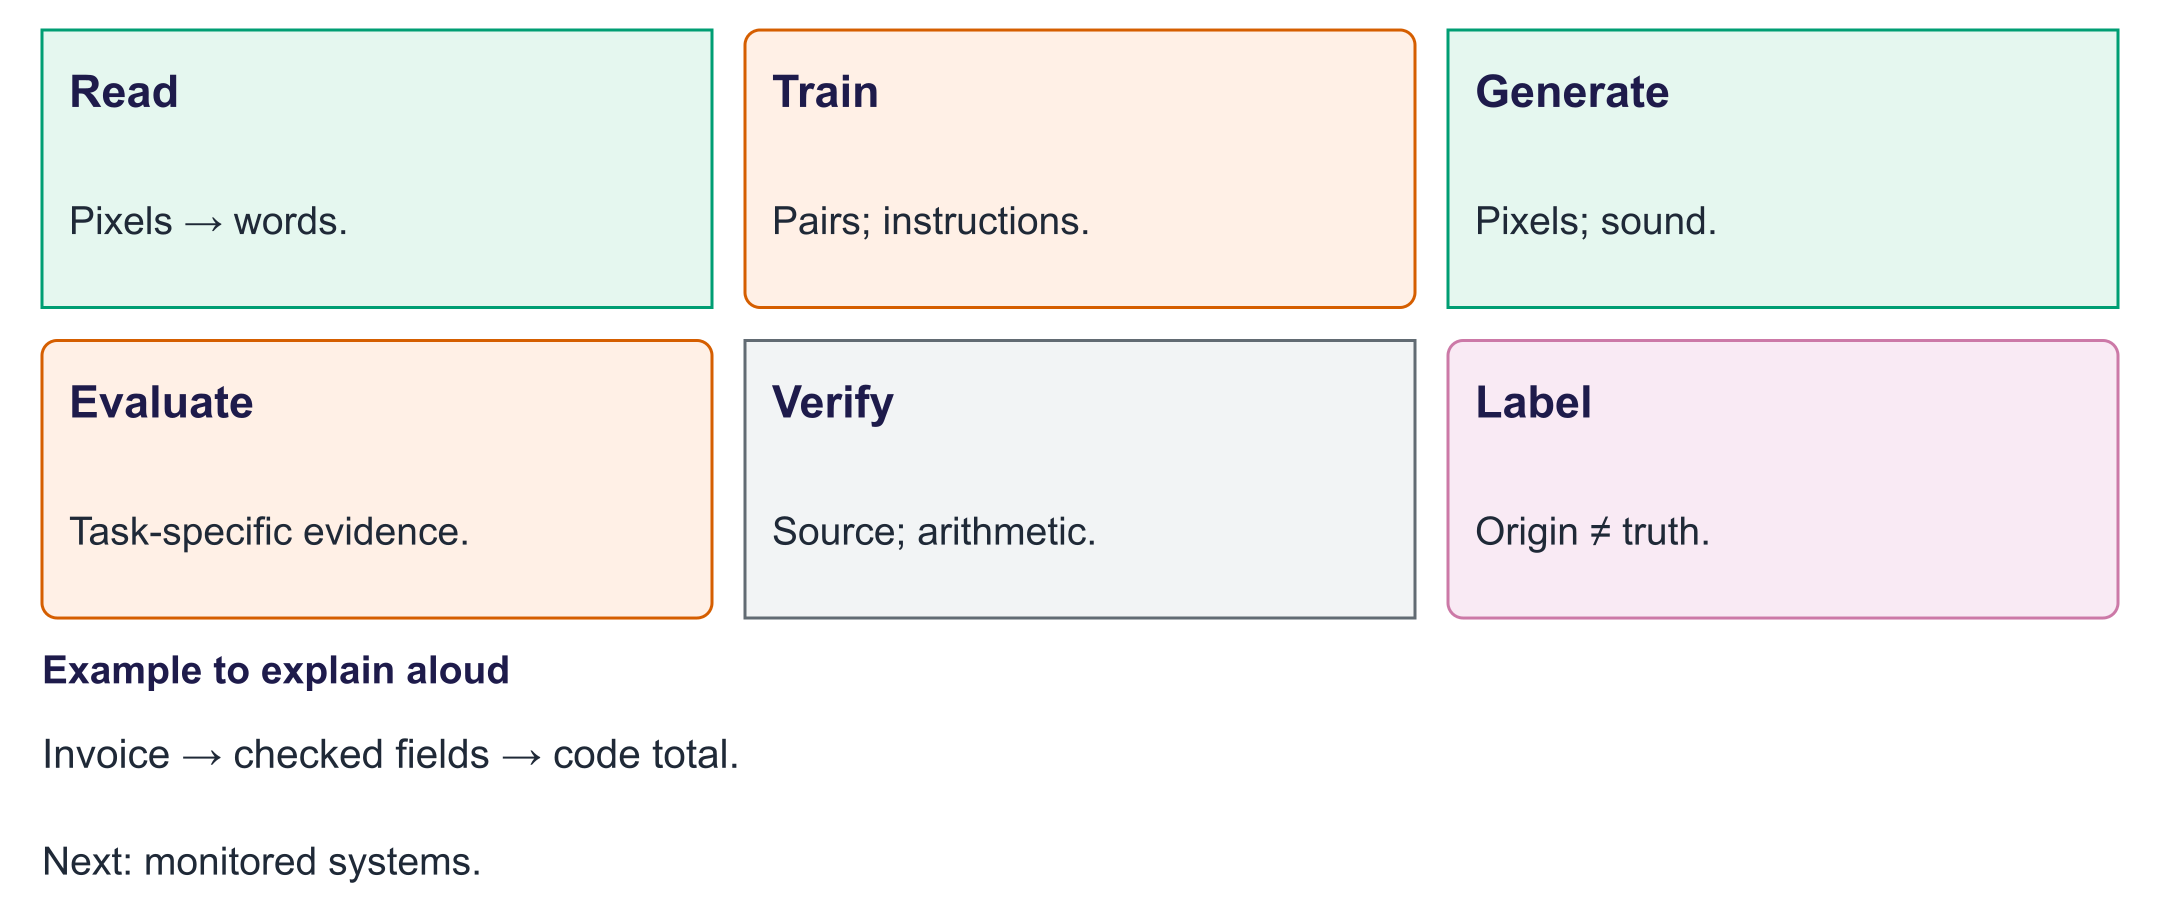

Invoice → checked fields → code total.

**Explain without looking:** Correct sum, wrong inputs?